### **MACHINE LEARNING**

1 Import Libraries and Packages

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif

2. Load and Understand the Dataset

In [6]:
#convert csv to dataframe
df = pd.read_csv("winedataset.csv")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [8]:
df.head(150)

,Id,class,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315_of_diluted_wines,Proline
0,1,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,2,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,3,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,4,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,5,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,146,3,13.16,3.57,2.15,21.0,102,1.50,0.55,0.43,1.30,4.00,0.60,1.68,830
146,147,3,13.88,5.04,2.23,20.0,80,0.98,0.34,0.40,0.68,4.90,0.58,1.33,415
147,148,3,12.87,4.61,2.48,21.5,86,1.70,0.65,0.47,0.86,7.65,0.54,1.86,625
148,149,3,13.32,3.24,2.38,21.5,92,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650


In [9]:
# Show info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Id                            178 non-null    int64  
 1   class                         178 non-null    int64  
 2   Alcohol                       178 non-null    float64
 3   Malicacid                     178 non-null    float64
 4   Ash                           178 non-null    float64
 5   Alcalinity_of_ash             178 non-null    float64
 6   Magnesium                     178 non-null    int64  
 7   Total_phenols                 178 non-null    float64
 8   Flavanoids                    178 non-null    float64
 9   Nonflavanoid_phenols          178 non-null    float64
 10  Proanthocyanins               178 non-null    float64
 11  Color_intensity               178 non-null    float64
 12  Hue                           178 non-null    float64
 13  OD280

In [10]:
# Show Mean etc
df.describe()

,Id,class,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315_of_diluted_wines,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,89.500000,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,51.528309,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,45.250000,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,89.500000,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,133.750000,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,178.000000,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [75]:
df.drop(columns="Id", inplace=True)

In [76]:
df['class'].value_counts()

,count
class,
2,71
1,59
3,48


3. Visualize the dataset

      Histogram

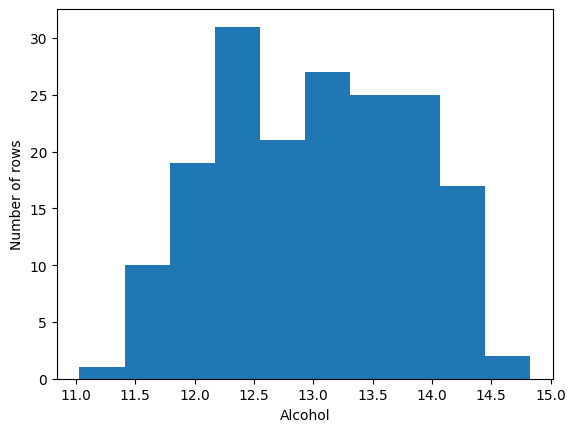

In [77]:
plt.hist(df['Alcohol'])
plt.xlabel('Alcohol')
plt.ylabel('Number of rows')
plt.show()

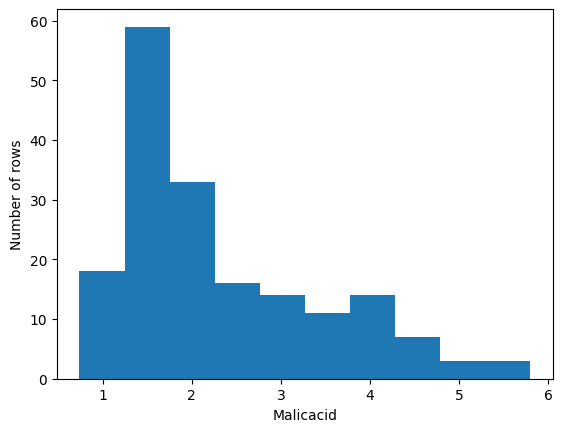

In [78]:
plt.hist(df['Malicacid'])
plt.xlabel('Malicacid')
plt.ylabel('Number of rows')
plt.show()

In [80]:
# Features
X = df.drop("class", axis=1)

# Labels
y = df['class'].values

In [81]:
F,p = f_classif(X,y)

feature_score = pd.DataFrame({
    "Feature": X.columns,
    "F_score": F,
    "p_value": p
})

feature_score = feature_score.sort_values(
    "F_score",
    ascending=False
)

feature_score

,Feature,F_score,p_value
6,Flavanoids,233.925873,3.598586e-50
12,Proline,207.920374,5.783168e-47
11,OD280_OD315_of_diluted_wines,189.972321,1.393105e-44
0,Alcohol,135.077624,3.319504e-36
9,Color_intensity,120.664018,1.162008e-33
10,Hue,101.316795,5.917662e-30
5,Total_phenols,93.733010,2.137670e-28
1,Malicacid,36.943425,4.127229e-14
3,Alcalinity_of_ash,35.771637,9.444473e-14
8,Proanthocyanins,30.271383,5.125359e-12


In [82]:
top_features = feature_score.head(5)


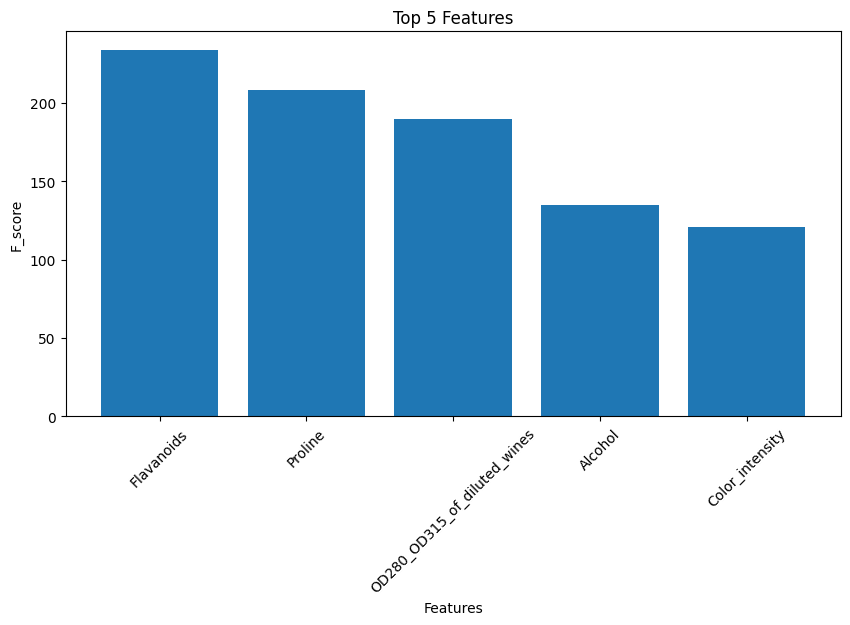

In [83]:
plt.figure(figsize=(10, 5))
plt.bar(top_features["Feature"], top_features["F_score"])

plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("F_score")
plt.title("Top 5 Features")
plt.show()

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 5)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(142, 14)
(142,)
(36, 14)
(36,)


In [25]:
print(X_train)

[[5.500e+01 1.374e+01 1.670e+00 ... 9.200e-01 3.200e+00 1.060e+03]
 [1.410e+02 1.293e+01 2.810e+00 ... 7.700e-01 2.310e+00 6.000e+02]
 [1.490e+02 1.332e+01 3.240e+00 ... 5.500e-01 1.620e+00 6.500e+02]
 ...
 [1.450e+02 1.225e+01 3.880e+00 ... 6.500e-01 2.000e+00 8.550e+02]
 [1.190e+02 1.277e+01 3.430e+00 ... 7.000e-01 2.120e+00 3.720e+02]
 [1.000e+02 1.229e+01 3.170e+00 ... 1.420e+00 2.830e+00 4.060e+02]]


In [84]:
knn = KNeighborsClassifier(n_neighbors=27)

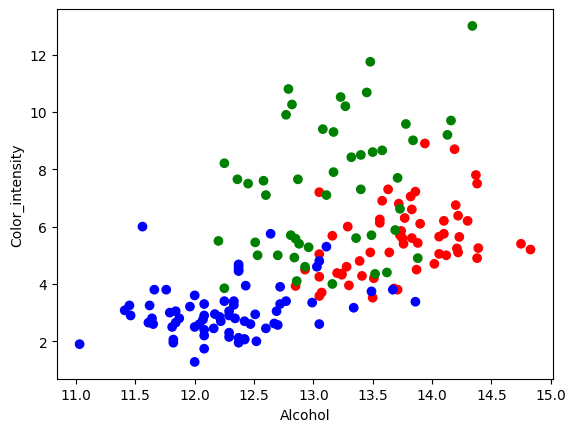

In [88]:
colors = {1: 'red',
          2: 'blue',
          3: 'green'}

plt.scatter(df['Alcohol'],
            df['Color_intensity'],
            c=df['class'].map(colors))

plt.xlabel("Alcohol")
plt.ylabel("Color_intensity")
plt.show()

In [85]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=27)

In [100]:
y_pred = knn.predict(X_test)
metrics.accuracy_score(y_test, y_pred)

0.8055555555555556

In [99]:
knn.predict([[1.56,2.45,3.78,4.89,5.16,6.78,7.60,8.86,9.08,10.57,11.11,12.31,13.56,14.79]])

array([2])

In [89]:
accuracy = metrics.accuracy_score(y_test, y_pred)
print('Accuracy:', accuracy)

Accuracy: 0.8055555555555556


In [90]:
metrics.confusion_matrix(y_test, y_pred)

array([[12,  5,  0],
       [ 2,  9,  0],
       [ 0,  0,  8]])

In [91]:
precision = metrics.precision_score(y_test, y_pred, average='weighted')
print('\nPrecision:', precision)


Precision: 0.8234126984126984


In [92]:
recall = metrics.recall_score(y_test, y_pred, average='weighted')
print('\nRecall:', recall)


Recall: 0.8055555555555556


In [93]:
f1 = metrics.f1_score(y_test, y_pred, average='weighted')
print('\nF1-Score:', f1)


F1-Score: 0.8078136200716846
